In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Base.csv')
print("Shape:", df.shape)
print(df.columns.tolist())

Shape: (1000000, 32)
['fraud_bool', 'income', 'name_email_similarity', 'prev_address_months_count', 'current_address_months_count', 'customer_age', 'days_since_request', 'intended_balcon_amount', 'payment_type', 'zip_count_4w', 'velocity_6h', 'velocity_24h', 'velocity_4w', 'bank_branch_count_8w', 'date_of_birth_distinct_emails_4w', 'employment_status', 'credit_risk_score', 'email_is_free', 'housing_status', 'phone_home_valid', 'phone_mobile_valid', 'bank_months_count', 'has_other_cards', 'proposed_credit_limit', 'foreign_request', 'source', 'session_length_in_minutes', 'device_os', 'keep_alive_session', 'device_distinct_emails_8w', 'device_fraud_count', 'month']


# Bank Account Application Fraud Analysis
This project analyses the Bank Account Fraud (BAF) dataset from Kaggle (NeurIPS 2022). It uses the base file, which contains 1,000,000 bank account applications. Each row is an application to open an account, not a transaction. The data is synthetic and was created from an anonymised real-world dataset to protect privacy. Therefore, the results describe patterns in this dataset, not actual bank activity. Each application has 30 features describing the applicant's details, application information, behaviour, device and session, as well as a fraud label (fraud_bool). The analysis uses Python, Pandas, NumPy, Matplotlib, Seaborn and Scikit-learn.
The analysis focuses on six questions:
1. How does the fraud rate differ across applicant and application characteristics?
2. Do behavioural variables differ between fraudulent and normal applications?
3. Are particular devices or application sources riskier?
4. Which features are most strongly associated with fraud?
5. Can simple rules, tested on later months, flag fraudulent applications?
6. How does a basic machine learning model compare with the rules?

# Data Check and Class Imbalance

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 32 columns):
 #   Column                            Non-Null Count    Dtype  
---  ------                            --------------    -----  
 0   fraud_bool                        1000000 non-null  int64  
 1   income                            1000000 non-null  float64
 2   name_email_similarity             1000000 non-null  float64
 3   prev_address_months_count         1000000 non-null  int64  
 4   current_address_months_count      1000000 non-null  int64  
 5   customer_age                      1000000 non-null  int64  
 6   days_since_request                1000000 non-null  float64
 7   intended_balcon_amount            1000000 non-null  float64
 8   payment_type                      1000000 non-null  object 
 9   zip_count_4w                      1000000 non-null  int64  
 10  velocity_6h                       1000000 non-null  float64
 11  velocity_24h                      1000

In [3]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


In [4]:
(df.select_dtypes("number") == -1).sum().sort_values(ascending=False).head(8)

prev_address_months_count       712920
bank_months_count               253635
current_address_months_count      4254
session_length_in_minutes         2015
credit_risk_score                  488
device_distinct_emails_8w          359
days_since_request                   0
name_email_similarity                0
dtype: int64

In [5]:
print(df["fraud_bool"].value_counts())
print()
print(df["fraud_bool"].value_counts(normalize=True)*100)

fraud_bool
0    988971
1     11029
Name: count, dtype: int64

fraud_bool
0    98.8971
1     1.1029
Name: proportion, dtype: float64


In [6]:
missing_coded = ["prev_address_months_count", "current_address_months_count",
                 "bank_months_count", "session_length_in_minutes",
                 "device_distinct_emails_8w"]
for col in missing_coded:
    df[col] = df[col].replace(-1, np.nan)
print(df[missing_coded].isnull().sum())

prev_address_months_count       712920
current_address_months_count      4254
bank_months_count               253635
session_length_in_minutes         2015
device_distinct_emails_8w          359
dtype: int64


The dataset contains 1,000,000 rows and 32 columns with no duplicate rows. Missing values are stored as -1 in five columns. After converting them, there are 973,183 missing values, mostly in prev_address_months_count (71.3% of applications) and bank_months_count (25.4%). Only 11,029 applications are fraudulent, or about 1 in 91. If every application were classified as normal, the result would still be 98.90% accuracy, but no fraud would be detected.

# Application Variables

Unique ages: 9


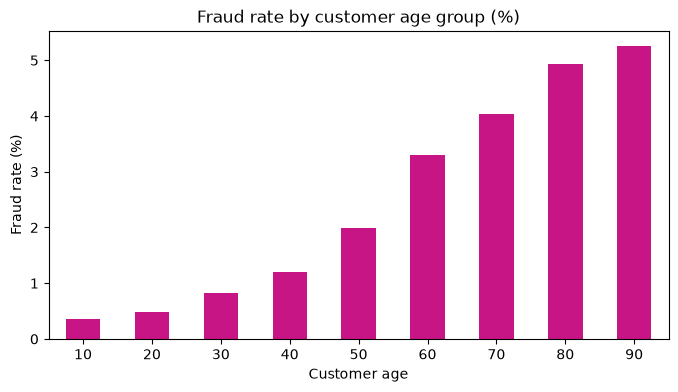

In [7]:
print("Unique ages:", df["customer_age"].nunique())
age_fraud = df.groupby("customer_age")["fraud_bool"].mean()*100
age_fraud.plot(kind="bar", figsize=(8, 4), color="mediumvioletred")
plt.title("Fraud rate by customer age group (%)")
plt.xlabel("Customer age")
plt.ylabel("Fraud rate (%)")
plt.xticks(rotation=0)
plt.show()

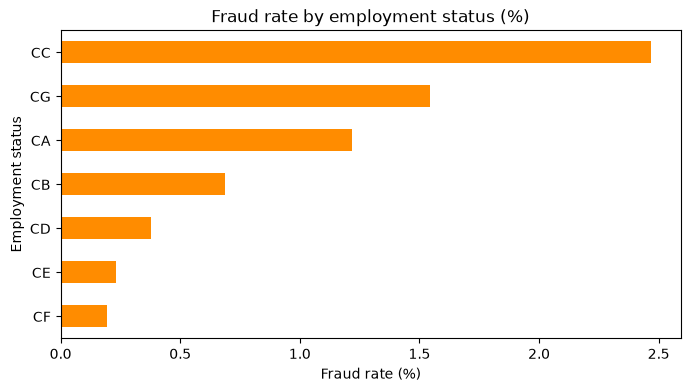

In [8]:
emp_fraud = df.groupby("employment_status")["fraud_bool"].mean().sort_values()*100
emp_fraud.plot(kind="barh", figsize=(8, 4), color="darkorange")
plt.title("Fraud rate by employment status (%)")
plt.xlabel("Fraud rate (%)")
plt.ylabel("Employment status")
plt.show()

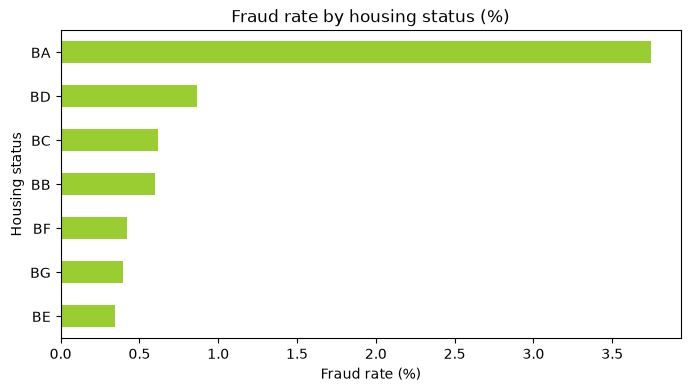

In [9]:
housing_fraud = df.groupby("housing_status")["fraud_bool"].mean().sort_values()*100
housing_fraud.plot(kind="barh", figsize=(8, 4), color="yellowgreen")
plt.title("Fraud rate by housing status (%)")
plt.xlabel("Fraud rate (%)")
plt.ylabel("Housing status")
plt.show()

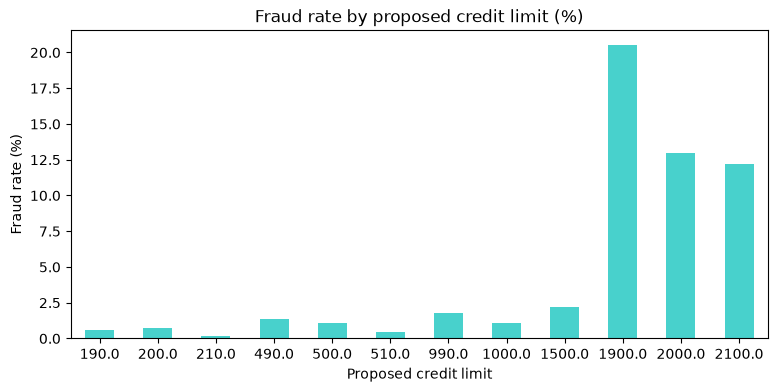

In [10]:
limit_fraud = df.groupby("proposed_credit_limit")["fraud_bool"].mean()*100
limit_fraud.plot(kind="bar", figsize=(9, 4), color="mediumturquoise")
plt.title("Fraud rate by proposed credit limit (%)")
plt.xlabel("Proposed credit limit")
plt.ylabel("Fraud rate (%)")
plt.xticks(rotation=0)
plt.show()

Fraud rate risesincreases with customer age, from around 0.4% in the 10s group to 5.3% in the 90s group. Housing status BA stands out at about 3.7%, more than four times the next group.The strongest difference appears in proposed credit limits between 1,900 and 2,100, where fraud rates range from roughly 12% to 20%, compared with around 2% or less for lower limits. These groups may contain fewer applications, so their results should be treated with caution. The status codes are anonymised, so their meaning is unknown. So older applicants and applications with higher proposed limits may need closer attention, but using age in fraud checks raises fairness concerns (see Limitations).

# Behavioural Variables

In [11]:
behaviour = ["velocity_6h", "velocity_24h", "velocity_4w", "name_email_similarity"]
df.groupby("fraud_bool")[behaviour].median()

,velocity_6h,velocity_24h,velocity_4w,name_email_similarity
fraud_bool,,,,
0,5324.540439,4751.027067,4914.578888,0.493571
1,4916.464728,4665.725851,4827.695220,0.292420


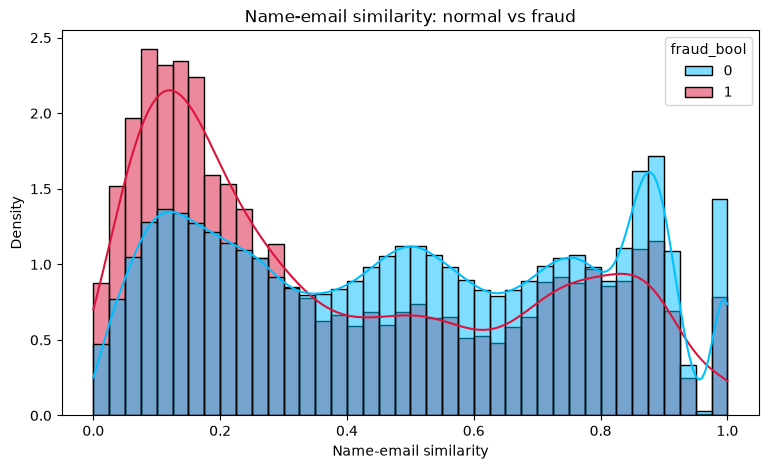

In [12]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="name_email_similarity", hue="fraud_bool",
             stat="density", common_norm=False, bins=40,
             palette=["deepskyblue", "crimson"], kde=True)
plt.title("Name-email similarity: normal vs fraud")
plt.xlabel("Name-email similarity")
plt.ylabel("Density")
plt.show()

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x="fraud_bool", y="velocity_6h", hue="fraud_bool",
            showfliers=False, palette=["mediumturquoise", "mediumvioletred"],
            legend=False)
plt.title("Application velocity (6 hours) by class")
plt.xlabel("fraud_bool (0 = normal, 1 = fraud)")
plt.ylabel("velocity_6h")
plt.show()

Fraudulent applications have a lower median name-email similarity than normal ones (0.29 vs 0.49). Their distribution is also more concentrated around lower values, especially near 0.1. Application velocity shows a much smaller difference. The 6-hour median is 4,916 for fraud and 5,325 for normal applications. The distributions overlap almost completely, so velocity does not help much in separating the two groups.

# Device and Session Variables

In [ ]:
os_fraud = df.groupby("device_os")["fraud_bool"].agg(["count", "mean"])
os_fraud["mean"] = os_fraud["mean"]*100
os_fraud = os_fraud.rename(columns={"count": "applications", "mean": "fraud_rate_%"})
os_fraud

In [ ]:
os_fraud["fraud_rate_%"].sort_values().plot(kind="barh", figsize=(8, 4), color="royalblue")
plt.title("Fraud rate by device operating system (%)")
plt.xlabel("Fraud rate (%)")
plt.ylabel("Device OS")
plt.show()

In [ ]:
pivot = df.pivot_table(values="fraud_bool", index="device_os",
                       columns="source", aggfunc="mean")*100
plt.figure(figsize=(7, 5))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlOrRd")
plt.title("Fraud rate (%) by device OS and application source")
plt.show()

In [ ]:
df.groupby("fraud_bool")[["session_length_in_minutes", "device_distinct_emails_8w"]].median()

In [ ]:
print(df["device_fraud_count"].value_counts().head())

Windows devices have the highest fraud rate (2.47%) almost five times Linux (0.52%). macOS follows at 1.40%. TELEAPP applications also have higher fraud rates than INTERNET applications across all device groups except x11. For x11, TELEAPP has no recorded fraud, although this group may be very small. The highest rate is 5.79% for Windows with TELEAPP. Session length is almost the same for both classes (median about 5.1 minutes), and device_fraud_count is 0 for all applications, so it does not help identify fraud. So device type and application source help identify risk, but session length does not.

# Which Features Are Associated with Fraud

In [ ]:
corr = df.corr(numeric_only=True)["fraud_bool"].drop("fraud_bool")
top = corr.reindex(corr.abs().sort_values(ascending=False).head(10).index).sort_values()
colors = ["crimson" if v>0 else "deepskyblue" for v in top.values]
plt.figure(figsize=(9, 5))
plt.barh(top.index, top.values, color=colors)
plt.title("Top 10 numeric features by correlation with fraud")
plt.xlabel("Correlation with fraud_bool (red = positive, blue = negative)")
plt.show()

In [ ]:
for col in missing_coded:
    rate_missing = df[df[col].isnull()]["fraud_bool"].mean()*100
    rate_present = df[df[col].notnull()]["fraud_bool"].mean()*100
    print(col, "| fraud rate when missing:", round(rate_missing, 2),
          "| when present:", round(rate_present, 2))

In [ ]:
results = []
for col in missing_coded:
    rate_missing = df.loc[df[col].isnull(), "fraud_bool"].mean()*100
    rate_present = df.loc[df[col].notnull(), "fraud_bool"].mean()*100
    results.append({
        "Feature": col,
        "Fraud rate (missing) %": rate_missing,
        "Fraud rate (present) %": rate_present
    })
missing_analysis = pd.DataFrame(results)
missing_analysis.round(2)

The correlations between numeric features and fraud are weak. The strongest are credit_risk_score, proposed_credit_limit and customer_age (all positive, about 0.06-0.07). keep_alive_session has a negative correlation of about -0.05. Weak linear correlation does not mean weak association, as the non-linear patterns in credit limit and housing status show. Missing values also seem to be linked to fraud in some columns. Whenprev_address_months_count is missing, the fraud rate is 1.42%, compared with 0.31% when it is present. For bank_months_count, the rates are 1.63% and 0.92%, respectively. The opposite pattern appears for current_address_months_count: 0.33% when missing and 1.11% when present, although only 4,254 rows have missing values in this column. Missing address history may be linked to fraud, but the pattern differs between columns, so it should not be treated as a reliable rule.

# Rules with a Time-Based Test

In [ ]:
print(df["month"].value_counts().sort_index())

In [ ]:
train = df[df["month"] <= 5]
test = df[df["month"] >= 6].copy()
print("Train:", len(train), "| fraud rate (%):", round(train["fraud_bool"].mean()*100, 2))
print("Test:", len(test), "| fraud rate (%):", round(test["fraud_bool"].mean()*100, 2))

In [ ]:
train.groupby("proposed_credit_limit")["fraud_bool"].agg(["count", "mean"])

In [ ]:
credit_limit_threshold = 1900
similarity_threshold = train["name_email_similarity"].quantile(0.10)
risk_threshold = train["credit_risk_score"].quantile(0.90)
test["Rule1"] = test["proposed_credit_limit"] >= credit_limit_threshold
test["Rule2"] = test["name_email_similarity"] < similarity_threshold
test["Rule3"] = test["credit_risk_score"] > risk_threshold
rule_columns = ["Rule1", "Rule2", "Rule3"]
test["RulesTriggered"] = test[rule_columns].sum(axis=1)
print(test["RulesTriggered"].value_counts().sort_index())

In [ ]:
total_fraud = test["fraud_bool"].sum()
base_rate = test["fraud_bool"].mean()*100
results = []
for n in [1, 2, 3]:
    flagged = test["RulesTriggered"] >= n
    caught = (flagged&(test["fraud_bool"] == 1)).sum()
    results.append({
        "Rules required": f"{n}+",
        "Flagged": flagged.sum(),
        "Fraud caught": caught,
        "Precision (%)": round(caught/flagged.sum()*100, 2),
        "Recall (%)": round(caught/total_fraud*100, 1)
    })
results_df = pd.DataFrame(results)
print("Fraud rate in test set (%):", round(base_rate, 2))
results_df

In [ ]:
fraud_by_rules = test.groupby("RulesTriggered")["fraud_bool"].mean()*100
bar_colors = ["yellowgreen", "gold", "darkorange", "red"][:len(fraud_by_rules)]
fraud_by_rules.plot(kind="bar", figsize=(8, 4), color=bar_colors)
plt.title("Fraud rate by number of rules triggered (test months)")
plt.xlabel("Rules triggered")
plt.ylabel("Fraud rate (%)")
plt.xticks(rotation=0)
plt.show()

Three rules were set using data from months 0-5 and then tested on months 6-7. The test set contains 205,011 applications, with a fraud rate of 1.40%. The rules look for a proposed credit limit of 1,900 or more, name-email similarity below 0.105 (the lowest 10% in months 0-5) and a credit risk score above 224 (the highest 10%). The fraud rate increases with the number of rules triggered, from around 0.9% with none to 24% with all three. Requiring at least two rules flags 2,619 applications with a precision of 11.45% (about eight times the base rate), but it detects only 10.4% of all fraud cases. Requiring just one rule detects 48.2% of fraud, but precision drops to 3.34%. The rules detect more fraud at the cost of more false alarms, while still missing most fraudulent applications.

# Basic Model

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import average_precision_score, precision_score, recall_score

feature_cols = [c for c in df.columns if c not in ["fraud_bool", "month"]]
X_all = pd.get_dummies(df[feature_cols])
X_all = X_all.fillna(-1)
is_train = df["month"] <= 5
X_train = X_all[is_train].sample(200000, random_state=42)
y_train = df.loc[X_train.index, "fraud_bool"]
X_test = X_all[~is_train]
y_test = df.loc[X_test.index, "fraud_bool"]

In [ ]:
model = RandomForestClassifier(n_estimators=100, max_depth=10,
                               class_weight="balanced", random_state=42, n_jobs=-1)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("PR-AUC:", average_precision_score(y_test, y_prob))

In [ ]:
rule_pred = (test["RulesTriggered"] >= 2).astype(int)
comparison = pd.DataFrame({
    "Model": ["Rule-based (2+ rules)", "Random Forest"],
    "Precision": [precision_score(y_test, rule_pred), precision_score(y_test, y_pred)],
    "Recall": [recall_score(y_test, rule_pred), recall_score(y_test, y_pred)]
}).round(3)
comparison

In [ ]:
comparison.set_index("Model").plot(kind="bar", figsize=(8, 5),
                                   color=["mediumturquoise", "mediumvioletred"])
plt.title("Rule-based approach vs Random Forest (test months)")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.show()

In [ ]:
importances = pd.Series(model.feature_importances_, index=X_train.columns)
top_imp = importances.sort_values(ascending=False).head(10).sort_values()
colors = plt.cm.viridis(np.linspace(0.2, 0.9, 10))
plt.figure(figsize=(9, 5))
plt.barh(top_imp.index, top_imp.values, color=colors)
plt.title("Top 10 features by Random Forest importance")
plt.xlabel("Importance")
plt.show()

Random Forest was trained on 200,000 applications from months 0-5 and tested on months 6-7. It detects 1,800 of 2,878 fraud cases (recall 0.63), but also produces 20,456 false alarms (precision 0.08), or about 11 false alarms for each detected fraud. Its PR-AUC of 0.125 is roughly nine times the fraud rate in the test set (0.014). Compared with the two-rule approach (precision 0.115, recall 0.104), the model detects six times as much fraud (1,800 vs 300 cases) but with lower precision. The model catches more fraud, but the rules give more reliable alerts.
The most important features are housing_status_BA, device_os_windows and the two address-history columns, consistent with Sections 2, 4 and 5. 

# Summary Dashboard

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle("Bank Account Fraud: Summary Dashboard", fontsize=16)

age_rate = df.groupby("customer_age")["fraud_bool"].mean()*100
age_rate.plot(kind="bar", ax=axes[0, 0], color="mediumvioletred")
axes[0, 0].set_title("Fraud rate by age group (%)")
axes[0, 0].set_xlabel("Customer age")
axes[0, 0].set_ylabel("Fraud rate (%)")

os_rate = df.groupby("device_os")["fraud_bool"].mean().sort_values()*100
os_rate.plot(kind="barh", ax=axes[0, 1], color="darkorange")
axes[0, 1].set_title("Fraud rate by device OS (%)")
axes[0, 1].set_xlabel("Fraud rate (%)")
axes[0, 1].set_ylabel("Device OS")

axes[1, 0].barh(top.index, top.values, color=["crimson" if v>0 else "deepskyblue" for v in top.values])
axes[1, 0].set_title("Top 10 correlations with fraud")
axes[1, 0].set_xlabel("Correlation")

fraud_by_rules.plot(kind="bar", ax=axes[1, 1], color="yellowgreen")
axes[1, 1].set_title("Fraud rate by rules triggered (%)")
axes[1, 1].set_xlabel("Rules triggered")
axes[1, 1].set_ylabel("Fraud rate (%)")

plt.tight_layout()
plt.savefig("dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
import ipywidgets as widgets
def show_fraud_rate(feature):
    rate = df.groupby(feature)["fraud_bool"].mean()*100
    rate.plot(kind="bar", figsize=(8, 4), color="crimson")
    plt.title(f"Fraud rate by {feature} (%)")
    plt.ylabel("Fraud rate (%)")
    plt.show()
widgets.interact(show_fraud_rate,
                 feature=["customer_age", "employment_status", "housing_status", "source", "device_os"])

# Conclusions
## Key findings
1. Fraud is rare in this dataset: only 1.10% of applications (about 1 in 91) are fraudulent. The share also changed over time, from 1.03% in months 0-5 to 1.40% in months 6-7.
2. Some groups have much higher fraud rates than others. Fraud increases with customer age (from around 0.4% to 5.3%), is highest for housing status BA (about 3.7%) and for Windows devices using the TELEAPP source (5.79%). Proposed credit limits of 1,900 or more also show high fraud rates.
3. Fraudulent applications usually have a lower name-email similarity (median 0.29 vs 0.49). Application velocity and session length are almost the same for both groups, so they are not very useful for identifying fraud.
4. No single numeric feature has a strong correlation with fraud (all correlations are about 0.07 or less). The more useful patterns come from categories, differences between groups and missing address history.
5. Simple rules are accurate when they trigger but miss many fraud cases. Two rules give a precision of 11.45% (about eight times the base rate) but detect only 10.4% of fraud. Using one rule detects 48.2% of fraud, but precision falls to 3.34%.
6. Random Forest detects more fraud (63%), but also produces many false alarms, around 11 for each fraud case detected. It detects six times more fraud than the two-rule approach, but alerts are less accurate.
The analysis helps identify which applications may carry a higher fraud risk, but neither the rules nor the model is reliable enough to make decisions on its own. They could be used to select applications for further manual review.
## Limitations
* The data is synthetic and anonymised. The meaning of categories such as housing status BA or employment status CC is unknown, so real banks may see different patterns.
* Only the base file was used, and the test period has just two months with a different fraud rate.
* The credit limit pattern was first identified using the full dataset and then confirmed on months 0-5, so the rule results may be slightly optimistic.
* Some groups, such as x11 devices with TELEAPP, may contain only a few applications, making their fraud rates less reliable.
* The model is a basic Random Forest trained on a sample of 200,000 applications. It was not tuned, and feature importance does not mean that a feature causes fraud.
* Fraud rises strongly with age. Other research on this dataset has found that models can produce more false alerts for applicants aged 50 and over. This raises concerns about unfair treatment if age is used in fraud decisions. This issue was not tested directly in this project.